# Fraud Detection: Rigour Pass

**Goal:** redo the evaluation honestly, so the score can be trusted.

**Problems found in notebook 02:**
1. The best model was chosen using the test set.
2. Amount and Time were scaled before the split.
3. The API sent columns in a different order from training.

**Author:** Martin James Ng'ang'a | github.com/M20Jay

---
## Section 1: Load the data

The raw table lives in Postgres. We read it from there so the notebook uses the same source as the rest of the project.

In [15]:
import sys
import os
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

print(sys.executable)

load_dotenv()
engine = create_engine(os.environ["DATABASE_URL"])
df = pd.read_sql("SELECT * FROM fraud_raw", engine)
df.columns = df.columns.str.lower()

print(df.shape)
print(df["class"].value_counts())

/Users/martinjames/Documents/GitHub/fraud-detection-pipeline/.venv/bin/python
(284807, 31)
class
0    284315
1       492
Name: count, dtype: int64


---
## Section 2: Split and seal the test set

We cut off 20 percent of the rows as a sealed test set. We do not look at it until Section 9. Everything else happens on the other 80 percent.

In [16]:
from sklearn.model_selection import train_test_split

FEATURES = ["time"] + [f"v{i}" for i in range(1,29)] + ["amount"]
TARGET = "class"

X= df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size =0.2, random_state=42,stratify=y)

print("train:", X_train.shape, " fraud:", int(y_train.sum()))
print("test :", X_test.shape, " fraud:", int(y_test.sum()))
print("fraud rate, train:", round(y_train.mean(),5))
print("fraud rate, test :", round(y_test.mean(),5))

train: (227845, 30)  fraud: 394
test : (56962, 30)  fraud: 98
fraud rate, train: 0.00173
fraud rate, test : 0.00172


In [17]:
# cache: save the split so the notebook doesn't need Postgres again
X_train.to_pickle("X_train.pkl")
X_test.to_pickle("X_test.pkl")
y_train.to_pickle("y_train.pkl")
y_test.to_pickle("y_test.pkl")


In [18]:
# reload cached split
import pandas as pd
X_train= pd.read_pickle("X_train.pkl")
X_test = pd.read_pickle("X_test.pkl")
y_train = pd.read_pickle("y_train.pkl")
y_test = pd.read_pickle("y_test.pkl")

---
## Section 3: Show the problems in the old approach

Show, with real numbers, what went wrong in notebook 02: scaling before the split, and the column order the API sent.

In [19]:
from sklearn.preprocessing import StandardScaler

old_way = StandardScaler().fit(df[["amount"]])
new_way = StandardScaler().fit(X_train[["amount"]])

print("old way (all rows)   mean:", old_way.mean_[0].round(3), " spread:", old_way.scale_[0].round(3))
print("new way  (train rows only) mean:", new_way.mean_[0].round(3), "spread:", new_way.scale_[0].round(3))

old way (all rows)   mean: 88.35  spread: 250.12
new way  (train rows only) mean: 88.176 spread: 250.722


In [20]:
trained_on = [f"v{i}" for i in range(1,29)] + ["amount_scaled", "time_scaled"]
api_sent = ["time"] + [f"v{i}" for i in range(1,29)] + ["amount"]

print("model was trained on, first 3:", trained_on[0:3], "last 2:", trained_on[-2:])
print("API sent,             first 3:", api_sent[0:3],   "last 2:", api_sent[-2:])


disagree = sum (a !=b for a,b in zip(trained_on, api_sent))

print("position that disagree:", disagree, "out of", len(trained_on))

model was trained on, first 3: ['v1', 'v2', 'v3'] last 2: ['amount_scaled', 'time_scaled']
API sent,             first 3: ['time', 'v1', 'v2'] last 2: ['v28', 'amount']
position that disagree: 30 out of 30


---
## Section 4: Build the safe pipeline
Build one pipeline where scaling and ADASYN happen inside, so they only ever see training data.

In [21]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

prep = ColumnTransformer(
    [("scale",StandardScaler(), ["time", "amount"])],
    remainder="passthrough",)

prep.fit(X_train) # Inspection only: the pipeline refits prep itself inside each CV fold.

out_names = prep.get_feature_names_out()
print("first 4 output columns:", list(out_names[:4]))
print("total output columns:", len (out_names))

first 4 output columns: ['scale__time', 'scale__amount', 'remainder__v1', 'remainder__v2']
total output columns: 30


In [22]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import ADASYN
from sklearn.linear_model import LogisticRegression

pipe = Pipeline([
    ("prep", prep),
    ("adasyn", ADASYN(random_state=42)),
    ("model", LogisticRegression(max_iter=1000)),
])

print(pipe.named_steps)

{'prep': ColumnTransformer(remainder='passthrough',
                  transformers=[('scale', StandardScaler(),
                                 ['time', 'amount'])]), 'adasyn': ADASYN(random_state=42), 'model': LogisticRegression(max_iter=1000)}


---
## Section 5: Compare models with cross-validation

Try four models (Logistic Regression, Random Forest, XGBoost, LightGBM) with 5-fold cross-validation and pick the winner by average PR-AUC, not by the test set. ADASYN runs inside each fold, on that fold's training rows only.

In [23]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest"      : RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "XGBoost"            : XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=-1),
    "LightGBM"           : LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1),
}

results = {}
for name, clf in models.items():
    p = Pipeline([
        ("prep", prep),
        ("adasyn", ADASYN(random_state=42)),
        ("model", clf),
    ])

    s = cross_val_score(p, X_train, y_train, cv=cv, scoring="average_precision")
    results[name]=s
    print(name, "mean:", s.mean().round(4), "std:", s.std().round(4))

Logistic Regression mean: 0.7468 std: 0.0494
Random Forest mean: 0.8341 std: 0.0265
XGBoost mean: 0.8333 std: 0.026
LightGBM mean: 0.7673 std: 0.0267


### 5b: Does ADASYN earn its place?

Re-run the top two models without resampling, handling the imbalance with class weights instead. If weights match or beat ADASYN, the simpler pipeline wins.

In [24]:
from sklearn.pipeline import Pipeline as SkPipeline

n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()
ratio = n_neg/ n_pos

no_adasyn ={
    "Random Forest (class_weight)" : RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1, class_weight="balanced"),
    "XGBoost (scale_pos_weight)" : XGBClassifier(
        eval_metric="logloss", random_state=42, n_jobs=-1, scale_pos_weight=ratio),
}

for name, clf in no_adasyn.items():
    p = SkPipeline([("prep", prep), ("model", clf)])
    s = cross_val_score(p, X_train, y_train, cv=cv, scoring ="average_precision")
    results[name]=s
    print(f"{name:30s}  mean:  {s.mean():.4}  std:  {s.std():.4}")



Random Forest (class_weight)    mean:  0.8335  std:  0.01838
XGBoost (scale_pos_weight)      mean:  0.8489  std:  0.0182


### 5c: Paired check: XGBoost weights vs XGBoost + ADASYN

Same 5 folds for both, so subtract fold by fold. Positive means weights won that fold.

In [25]:
diff = results["XGBoost (scale_pos_weight)"] - results["XGBoost"]
print("per-fold difference:", diff.round(4))
print("folds where weights won:", (diff > 0).sum(), "out of 5")

per-fold difference: [ 0.0594  0.0076  0.023  -0.011  -0.0012]
folds where weights won: 3 out of 5


**Finding:** ADASYN gave no reliable improvement. For XGBoost, class weights beat ADASYN in 3 of 5 folds (mean +0.016), but one fold drove most of that gain, so the evidence is weak. For Random Forest the two were tied (0.8341 vs 0.8335). Class weights are simpler, faster and steadier (std ≈ 0.018 vs ≈ 0.026), so **ADASYN is removed from the final pipeline.**

### 5d: LightGBM with class weights instead of ADASYN (same folds, same metric)


In [26]:
# 5d-1: LightGBM, scale_pos_weight = ratio (about 577), no ADASYN  -> mean 0.0377 (collapsed; see 5d-2, 5d-3)
lgbm_w = LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1, scale_pos_weight=ratio)
p = SkPipeline([("prep", prep), ("model", lgbm_w)])
s = cross_val_score(p, X_train, y_train, cv=cv, scoring="average_precision")
results["LightGBM (scale_pos_weight)"] = s
print(f"{'LightGBM (scale_pos_weight)':30s} mean: {s.mean():.4f}  std: {s.std():.4f}")

LightGBM (scale_pos_weight)    mean: 0.0281  std: 0.0138


In [27]:
# 5d-2: LightGBM, scale_pos_weight = sqrt(ratio) (about 24), no ADASYN  -> mean 0.2274, std 0.0978 (still poor, unstable)
lgbm_w = LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1, scale_pos_weight=ratio**0.5)
p = SkPipeline([("prep", prep), ("model", lgbm_w)])
s = cross_val_score(p, X_train, y_train, cv=cv, scoring="average_precision")
results["LightGBM (sqrt weight)"] = s
print(f"{'LightGBM (sqrt weight)':30s} mean: {s.mean():.4f}  std: {s.std():.4f}")

LightGBM (sqrt weight)         mean: 0.1219  std: 0.0583


In [28]:
# 5d-3: LightGBM plain, no ADASYN, no weights
p = SkPipeline([("prep", prep), ("model", LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1))])
s = cross_val_score(p, X_train, y_train, cv=cv, scoring="average_precision")
results["LightGBM (plain)"] = s
print(f"{'LightGBM (plain)':30s} mean: {s.mean():.4f}  std: {s.std():.4f}")

LightGBM (plain)               mean: 0.1190  std: 0.0498


In [29]:
# 5d-4: overfitting check: plain LightGBM, one fold, train vs validation PR-AUC
from sklearn.metrics import average_precision_score

tr_idx, va_idx = next(cv.split(X_train, y_train))
m = SkPipeline([("prep", prep), ("model", LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1))])
m.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])

for label, idx in [("train", tr_idx), ("validation", va_idx)]:
    p_hat = m.predict_proba(X_train.iloc[idx])[:, 1]
    print(label, round(average_precision_score(y_train.iloc[idx], p_hat), 4))

train 0.256
validation 0.1513


### 5d: LightGBM investigation (open item)

With default settings LightGBM scored 0.77 with ADASYN, but only 0.04 / about 0.21 / 0.13 with full weights, sqrt weights and no help (the sqrt run gave 0.21 to 0.23 between identical runs, so LightGBM is not fully repeatable here). A train-vs-validation check on one fold gave 0.256 / 0.151, so it is underfitting, not overfitting. Cause not yet found. Excluded from the final comparison until resolved.

### 5e: Logistic Regression with class weights instead of ADASYN (same folds, same metric)


In [30]:
lr_w = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
p = SkPipeline([("prep", prep), ("model", lr_w)])
s = cross_val_score(p, X_train, y_train, cv=cv, scoring="average_precision")
results["Logistic Regression (class_weight)"] = s
print(f"{'Logistic Regression (class_weight)':36s} mean: {s.mean():.4f}  std: {s.std():.4f}")

Logistic Regression (class_weight)   mean: 0.7568  std: 0.0517


### 5f: Summary of every run, sorted by mean PR-AUC

In [31]:
import pandas as pd

summary = pd.DataFrame({
    "mean" : {k: v.mean() for k, v in results.items()},
    "std": {k: v.std() for k, v in results.items()}
}).round(4).sort_values("mean", ascending=False)

print(summary)

                                      mean     std
XGBoost (scale_pos_weight)          0.8489  0.0182
Random Forest                       0.8341  0.0265
Random Forest (class_weight)        0.8335  0.0184
XGBoost                             0.8333  0.0260
LightGBM                            0.7673  0.0267
Logistic Regression (class_weight)  0.7568  0.0517
Logistic Regression                 0.7468  0.0494
LightGBM (sqrt weight)              0.1219  0.0583
LightGBM (plain)                    0.1190  0.0498
LightGBM (scale_pos_weight)         0.0281  0.0138


**Section 5 conclusion**

Best model: **XGBoost with scale_pos_weight** (PR-AUC 0.8489 ± 0.018), ahead of Random Forest (0.8341 / 0.8335) by about one fold-spread, so a modest edge. ADASYN gave no reliable gain for Random Forest, XGBoost or Logistic Regression; class weights are simpler and steadier, so **ADASYN is dropped from the final pipeline**. LightGBM underfit without resampling (train 0.256, validation 0.151) and is excluded pending investigation; its scores also varied between identical runs. Test set not used.

---
### 6: Compute the out-of-fold probabilities

Re-run the winning model (XGBoost with scale_pos_weight, no ADASYN) through the same 5 folds, this time keeping the predicted fraud probability for every training row. Each probability comes from a model that never saw that row.

In [32]:
# 6: Out-of-fold fraud probabilities for the chosen model (XGBoost + scale_pos_weight, no ADASYN)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import average_precision_score

best_clf = XGBClassifier(eval_metric="logloss", random_state=42, n_jobs=-1, scale_pos_weight=ratio)
best_pipe = SkPipeline([("prep", prep), ("model", best_clf)])

oof_proba = cross_val_predict(
    best_pipe, X_train, y_train, cv=cv, method="predict_proba",
)[:, 1]

print("rows:", len(oof_proba), "of", len(y_train))
print("OOF PR-AUC:", round(average_precision_score(y_train, oof_proba), 4))

rows: 227845 of 227845
OOF PR-AUC: 0.846


### 6a: Look inside the probabilities


In [33]:
# 6a: Look inside oof_proba: first 8 rows (normal) vs first 5 truly-fraud rows
print(oof_proba[:8])
print("fraud rows, first 5 probabilities:", oof_proba[y_train.values==1][:5].round(4))

[1.1390426e-07 2.5162208e-07 2.1234291e-06 1.7058498e-07 1.2292253e-06
 9.4920915e-07 6.7128390e-06 9.5229558e-07]
fraud rows, first 5 probabilities: [1.     1.     0.9992 0.0165 1.    ]


### 6b: How many real frauds are missed at the default 0.5 cutoff?



In [34]:
fraud_probs = oof_proba[y_train.values==1]
print("fraud rows scored below 0.5:", (fraud_probs < 0.5).sum(), "of", len(fraud_probs))

fraud rows scored below 0.5: 79 of 394


### 6c: Precision vs recall at several cutoffs


In [35]:
from sklearn.metrics import average_precision_score, recall_score, precision_score

for t in [0.1, 0.3, 0.5, 0.7, 0.9]:
    flagged = oof_proba >= t          # True = the model would call this row fraud
    print(f"threshold {t}:  flagged {flagged.sum():5d}  "
          f"recall {recall_score(y_train, flagged):.3f}  "
          f"precision {precision_score(y_train, flagged):.3f}")

threshold 0.1:  flagged   401  recall 0.827  precision 0.813
threshold 0.3:  flagged   360  recall 0.812  precision 0.889
threshold 0.5:  flagged   349  recall 0.799  precision 0.903
threshold 0.7:  flagged   341  recall 0.799  precision 0.924
threshold 0.9:  flagged   326  recall 0.787  precision 0.951


In [36]:
# save the out-of-fold probabilities so we do not recompute them
import numpy as np
np.save("oof_proba.npy", oof_proba)

# save the true labels next to the saved scores, so we can reload both later
y_train.to_csv("y_train.csv", index=False)


---
## Section 7: Calibration

Make the predicted probabilities match how often fraud really happens, using the out-of-fold scores.

In [44]:
# Section 7 setup: load the saved out-of-fold scores
import numpy as np
oof_proba = np.load("oof_proba.npy")

In [ ]:

#calibration check - do predicted probabilities match real fraud rates?
from sklearn.calibration import calibration_curve

frac_fraud, mean_pred = calibration_curve(y_train, oof_proba, n_bins=10, strategy="quantile")
for p, f in zip(mean_pred, frac_fraud):
    print(f"model said {p:.4f}   actual fraud rate {f:.4f}")

model said 0.0000   actual fraud rate 0.0000
model said 0.0000   actual fraud rate 0.0000
model said 0.0000   actual fraud rate 0.0000
model said 0.0000   actual fraud rate 0.0001
model said 0.0000   actual fraud rate 0.0000
model said 0.0000   actual fraud rate 0.0000
model said 0.0000   actual fraud rate 0.0000
model said 0.0000   actual fraud rate 0.0004
model said 0.0000   actual fraud rate 0.0004
model said 0.0160   actual fraud rate 0.0163


### 7b: Look by score range

Group rows by their score (0–0.1, 0.1–0.2, ...) and compare with how often fraud really happens in each.

In [38]:
import numpy as np
oof_proba = np.load("oof_proba.npy")
edges = np.linspace(0,1,11)
bin_id = np.digitize(oof_proba, edges[1:-1])

for b in range(10):
    mask=bin_id == b
    if mask.sum() == 0:
        continue

    print(f"score {edges[b]:.1f}-{edges[b+1]:.1f}: rows {mask.sum():6d}  model said {oof_proba[mask].mean():.3f}  actual {y_train.values[mask].mean():.3f}")

score 0.0-0.1: rows 227444  model said 0.000  actual 0.000
score 0.1-0.2: rows     29  model said 0.142  actual 0.138
score 0.2-0.3: rows     12  model said 0.255  actual 0.167
score 0.3-0.4: rows      5  model said 0.355  actual 0.400
score 0.4-0.5: rows      6  model said 0.444  actual 0.500
score 0.5-0.6: rows      3  model said 0.571  actual 0.000
score 0.6-0.7: rows      5  model said 0.670  actual 0.000
score 0.7-0.8: rows      4  model said 0.714  actual 0.250
score 0.8-0.9: rows     11  model said 0.852  actual 0.364
score 0.9-1.0: rows    326  model said 0.999  actual 0.951


### 7b plot: the same table as a picture

One dot per score range. Dots on the dashed diagonal mean the model's score matches how often fraud really happens.

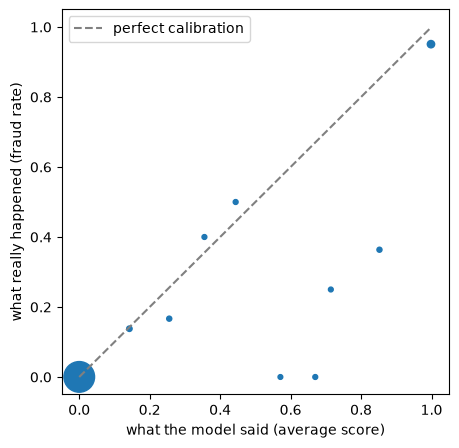

In [39]:
import matplotlib.pyplot as plt

claimed, actual, rows = [], [], []
for b in range(10):
    mask = bin_id == b
    if mask.sum() == 0:
        continue
    claimed.append(oof_proba[mask].mean())
    actual.append(y_train.values[mask].mean())
    rows.append(mask.sum())

plt.figure(figsize=(5,5))
plt.plot([0,1], [0,1], "--", color="grey", label="perfect calibration")
plt.scatter(claimed, actual, s=[10 + r** 0.5 for r in rows])
plt.xlabel("what the model said (average score)")
plt.ylabel("what really happened (fraud rate)")
plt.legend()
plt.show()

### 7c: Fix the scores with isotonic regression

Learn a conversion from the model's score to the real fraud rate, fitting it on four folds and applying it to the fifth, so the result is fair.

In [40]:
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold

y = y_train.values
cal_proba = np.zeros(len(oof_proba))
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for fit_idx, apply_idx in skf.split(oof_proba,y):
    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(oof_proba[fit_idx], y[fit_idx])
    cal_proba[apply_idx] = iso.predict(oof_proba[apply_idx])
print(cal_proba[:5].round(4), cal_proba.min(), cal_proba.max())


[0.     0.     0.0002 0.     0.0001] 2.0861889424850233e-05 1.0


### 7d: compare Brier score and PR-AUC before and after calibration


In [41]:
from sklearn.metrics import brier_score_loss, average_precision_score

print("Brier before:", round(brier_score_loss(y, oof_proba),6))
print("Brier After:", round(brier_score_loss(y, cal_proba),6))
print("PR-AUC before:", round(average_precision_score(y, oof_proba),4))
print("PR_AUC after:", round(average_precision_score(y, cal_proba),4))


Brier before: 0.000443
Brier After: 0.000419
PR-AUC before: 0.846
PR_AUC after: 0.8311


### 7e: Platt scaling - a smooth S-curve from score to real fraud rate, fitted fold by fold


In [42]:
from sklearn.linear_model import LogisticRegression

eps = 1e-6
p = np.clip(oof_proba, eps, 1-eps)
logit = np.log(p / (1-p)).reshape(-1,1)

platt_proba = np.zeros(len(oof_proba))

for fit_idx, apply_idx in skf.split(oof_proba,y):
    platt = LogisticRegression()
    platt.fit(logit[fit_idx], y[fit_idx])
    platt_proba[apply_idx] = platt.predict_proba(logit[apply_idx])[:,1]


print("Brier raw:   ", round(brier_score_loss(y, oof_proba),6))
print("Brier Platt: ", round(brier_score_loss(y,platt_proba),6))
print("PR-AUC raw:",   round(average_precision_score(y, oof_proba), 4))
print("PR-AUC platt:", round(average_precision_score(y, platt_proba),4))


Brier raw:    0.000443
Brier Platt:  0.000414
PR-AUC raw: 0.846
PR-AUC platt: 0.8361


### 7 conclusion: keep the raw scores

Raw out-of-fold scores were already close to honest (Brier 0.000443, against about 0.0017 for no skill). Isotonic (0.000419) and Platt (0.000414) improved the Brier score only slightly, and both lowered PR-AUC in the fold-wise comparison (0.846 to 0.831 and 0.836), partly because each fold fits its own curve. The gain is too small to justify extra complexity, so the final model uses raw scores.

---
## Section 8: Costs and the threshold

State the cost of a missed fraud and of a false alarm, with sources, and choose the threshold that costs least.

---
## Section 9: Score the sealed test set once

Score the sealed test set one time. Report PR-AUC with a range, and the money saved.

---
## Section 10: Drift monitoring

Set up a check that tells us when live transactions stop looking like the training data.

---
## Section 11: Move it into src, then tests and CI

Move the finished code into src/, add tests and CI, and update the README with the honest number.

---
## Section 12: Redeploy the API

Serve the fixed model again, with the correct input handling and threshold.